In [2]:
import sys
sys.path.append("..")

import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import classification_report, f1_score, ConfusionMatrixDisplay
from sklearn.utils.class_weight import compute_sample_weight

from src.features import build_features

d = np.load("../data/processed/beats.npz")
CLASSES = ["N", "S", "V", "F"]

def load(split):
    X, y, rr, g = d[f"X_{split}"], d[f"y_{split}"], d[f"rr_{split}"], d[f"g_{split}"]
    m = y != 4                      # حذف کلاس Q
    X, y, rr, g = X[m], y[m], rr[m], g[m]
    return build_features(X, rr, g), y, g

F_train, y_train, g_train = load("train")
F_test,  y_test,  g_test  = load("test")
print(F_train.shape, F_test.shape)   # (50969, 56) (49661, 56)

(50969, 57) (49661, 57)


In [3]:
gkf = GroupKFold(n_splits=5)

def oof_proba(make_model, F, y, g):
    proba = np.zeros((len(y), 4))
    for tr, va in gkf.split(F, y, g):
        model = make_model()
        model.fit(F[tr], y[tr], sample_weight=compute_sample_weight("balanced", y[tr]))
        p = np.zeros((len(va), 4))
        p[:, model.classes_] = model.predict_proba(F[va])
        proba[va] = p
    return proba

makers = {
    "RandomForest": lambda: RandomForestClassifier(
        n_estimators=200, min_samples_leaf=2, n_jobs=-1, random_state=42),
    "HistGradientBoosting": lambda: HistGradientBoostingClassifier(
        max_iter=200, learning_rate=0.1, random_state=42),
}

oof = {}
for name, mk in makers.items():
    oof[name] = oof_proba(mk, F_train, y_train, g_train)
    pred = oof[name].argmax(1)
    print(name, "| macro F1 (CV):", round(f1_score(y_train, pred, average="macro"), 3))

RandomForest | macro F1 (CV): 0.449


d:\ANACONDA\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "d:\ANACONDA\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "d:\ANACONDA\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "d:\ANACONDA\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass

HistGradientBoosting | macro F1 (CV): 0.471


In [4]:
for name, p in oof.items():
    print("=====", name)
    print(classification_report(y_train, p.argmax(1), target_names=CLASSES, digits=3, zero_division=0))

===== RandomForest
              precision    recall  f1-score   support

           N      0.970     0.934     0.952     45824
           S      0.507     0.118     0.191       943
           V      0.513     0.891     0.651      3788
           F      0.000     0.000     0.000       414

    accuracy                          0.909     50969
   macro avg      0.498     0.486     0.449     50969
weighted avg      0.920     0.909     0.908     50969

===== HistGradientBoosting
              precision    recall  f1-score   support

           N      0.980     0.892     0.934     45824
           S      0.295     0.381     0.332       943
           V      0.463     0.914     0.615      3788
           F      0.002     0.002     0.002       414

    accuracy                          0.877     50969
   macro avg      0.435     0.547     0.471     50969
weighted avg      0.921     0.877     0.891     50969



In [5]:
def tune_weights(proba, y, grid=(0.25, 0.5, 1, 2, 4, 8, 16)):
    w = np.ones(4)
    best = f1_score(y, (proba * w).argmax(1), average="macro")
    for _ in range(3):
        for c in range(1, 4):
            for v in grid:
                w2 = w.copy()
                w2[c] = v
                s = f1_score(y, (proba * w2).argmax(1), average="macro")
                if s > best:
                    best, w = s, w2
    return w, best

results = {}
for name, p in oof.items():
    w, s = tune_weights(p, y_train)
    results[name] = (w, s)
    print(name, "| weights:", w, "| tuned CV macro F1:", round(s, 3))

best_name = max(results, key=lambda k: results[k][1])
print("بهترین مدل:", best_name)

RandomForest | weights: [1. 4. 1. 8.] | tuned CV macro F1: 0.522
HistGradientBoosting | weights: [ 1.    4.    0.25 16.  ] | tuned CV macro F1: 0.514
بهترین مدل: RandomForest


In [6]:
w = results[best_name][0]
model = makers[best_name]()
model.fit(F_train, y_train, sample_weight=compute_sample_weight("balanced", y_train))

proba = np.zeros((len(y_test), 4))
proba[:, model.classes_] = model.predict_proba(F_test)
pred = (proba * w).argmax(1)

print(classification_report(y_test, pred, target_names=CLASSES, digits=3))
print("macro F1 (test):", round(f1_score(y_test, pred, average="macro"), 3))

              precision    recall  f1-score   support

           N      0.957     0.849     0.900     44218
           S      0.184     0.158     0.170      1836
           V      0.965     0.902     0.933      3219
           F      0.055     0.822     0.102       388

    accuracy                          0.827     49661
   macro avg      0.540     0.683     0.526     49661
weighted avg      0.922     0.827     0.869     49661

macro F1 (test): 0.526


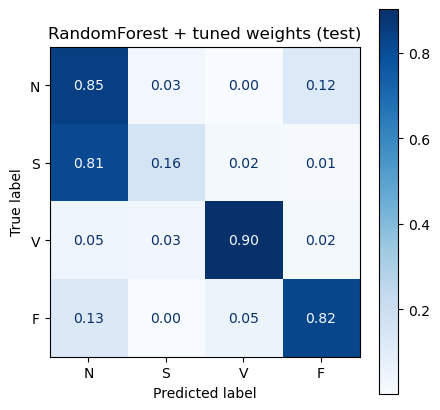

In [7]:
fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred, display_labels=CLASSES,
    normalize="true", values_format=".2f", cmap="Blues", ax=ax)
plt.title(f"{best_name} + tuned weights (test)")
plt.show()